# Classification Baseline: Logistic Regression

**Goal:** predict `is_delayed` using only features available at purchase time. Fit preprocessing exclusively on the training partition, select a decision threshold using validation data, and evaluate the untouched test partition once.

**Inputs:** `data/processed/splits/{train,validation,test}.parquet` and `split_manifest.json` from notebook 04. **Outputs:** model, metrics, and predictions under `models/baseline/`.

**Important limitation:** the chronological split is based on purchase dates, not label-availability dates. Orders purchased near the boundary may have delivery outcomes unknown at the next period's start. This baseline is a retrospective benchmark, **not** yet a fully leakage-safe historical backtest. The dataset also includes delivered orders only.

## 1. Imports and input contract

In [8]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, f1_score, confusion_matrix,
                             precision_recall_curve, classification_report, brier_score_loss)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd().resolve().parent
SPLIT_DIR = PROJECT_ROOT / "data" / "processed" / "splits"
OUTPUT_DIR = PROJECT_ROOT / "models" / "baseline"
manifest = json.loads((SPLIT_DIR / "split_manifest.json").read_text(encoding="utf-8"))
frames = {name: pd.read_parquet(SPLIT_DIR / f"{name}.parquet", engine="pyarrow") for name in ("train", "validation", "test")}
FEATURE_COLUMNS = manifest["feature_columns"]
TARGET = "is_delayed"
assert TARGET in manifest["target_columns"]
assert "delivery_time_days" not in FEATURE_COLUMNS
assert not set(FEATURE_COLUMNS) & set(manifest["target_columns"] + manifest["metadata_columns"])
for name, df in frames.items():
    assert set(FEATURE_COLUMNS + [TARGET]).issubset(df.columns)
    assert df["order_id"].is_unique
    assert df[TARGET].notna().all() and df[TARGET].isin([0, 1]).all()
    assert df[FEATURE_COLUMNS].select_dtypes(exclude=["number", "bool"]).empty, "Unexpected nonnumeric feature"
    print(name, df.shape, df[TARGET].value_counts().to_dict())

train (67529, 19) {0: 62239, 1: 5290}
validation (14471, 19) {0: 13847, 1: 624}
test (14470, 19) {0: 13850, 1: 620}


## 2. Temporal and feature audit

Preprocessing is learned on **train only**. Missing geographic values are imputed using training medians. Boolean and numeric columns are cast to floating point for a consistent sklearn input.

The schema allowlist is inherited from notebook 03. Its assumptions about order-item availability must be verified against the intended production inference time. In particular, aggregated seller/geolocation reference tables must not incorporate future-only knowledge.

In [9]:
assert frames["train"]["order_purchase_timestamp"].max() < frames["validation"]["order_purchase_timestamp"].min()
assert frames["validation"]["order_purchase_timestamp"].max() < frames["test"]["order_purchase_timestamp"].min()
assert set(frames["train"]["order_id"]).isdisjoint(frames["validation"]["order_id"])
assert set(frames["train"]["order_id"]).isdisjoint(frames["test"]["order_id"])
assert set(frames["validation"]["order_id"]).isdisjoint(frames["test"]["order_id"])

X = {name: df[FEATURE_COLUMNS].astype("float64") for name, df in frames.items()}
y = {name: df[TARGET].astype(int) for name, df in frames.items()}
assert all(y[name].nunique() == 2 for name in frames)
print(pd.DataFrame({name: {"n": len(y[name]), "positive": int(y[name].sum()),
                           "prevalence": y[name].mean()} for name in frames}).T)

                  n  positive  prevalence
train       67529.0    5290.0    0.078337
validation  14471.0     624.0    0.043121
test        14470.0     620.0    0.042847


## 3. Fit preprocessing and baseline classifier

The model uses median imputation, standardization and regularized logistic regression. A constant-probability classifier provides a no-skill PR-AUC reference (equal to positive prevalence).

In [10]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("scaler", StandardScaler()),
])
preprocess = ColumnTransformer([("numeric", numeric_pipeline, FEATURE_COLUMNS)], remainder="drop")
model = Pipeline([
    ("preprocess", preprocess),
    ("classifier", LogisticRegression(max_iter=2000, solver="lbfgs", random_state=42)),
])
model.fit(X["train"], y["train"])
print("Baseline fitted on training data only")

Baseline fitted on training data only


## 4. Validation metrics and threshold selection

Use **Average Precision (AP)** as the primary ranking metric. PR-AUC here means sklearn's non-interpolated `average_precision_score`. Evaluate threshold-independent metrics first; choose a classification threshold **only on validation** to maximize F1 as a simple baseline decision policy. The choice of F1 is illustrative and can be replaced by business costs later. Never tune the threshold on test data.

Validation AP: 0.0597
Validation ROC-AUC: 0.6060
Validation prevalence (no-skill AP): 0.0431
Selected validation F1 threshold: 0.236867
Validation F1 at threshold: 0.1177


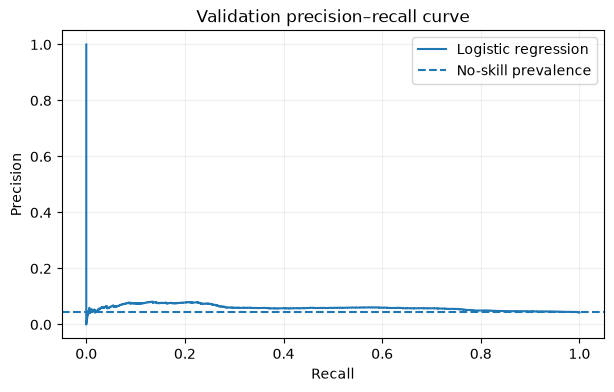

In [11]:
val_scores = model.predict_proba(X["validation"])[:, 1]
precision_curve, recall_curve, thresholds = precision_recall_curve(y["validation"], val_scores)
threshold_f1 = 2 * precision_curve[:-1] * recall_curve[:-1] / np.maximum(
    precision_curve[:-1] + recall_curve[:-1], 1e-12)
assert len(thresholds) > 0
best_index = int(np.argmax(threshold_f1))
selected_threshold = float(thresholds[best_index])
print(f"Validation AP: {average_precision_score(y['validation'], val_scores):.4f}")
print(f"Validation ROC-AUC: {roc_auc_score(y['validation'], val_scores):.4f}")
print(f"Validation prevalence (no-skill AP): {y['validation'].mean():.4f}")
print(f"Selected validation F1 threshold: {selected_threshold:.6f}")
print(f"Validation F1 at threshold: {threshold_f1[best_index]:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(recall_curve, precision_curve, label="Logistic regression")
plt.axhline(y["validation"].mean(), linestyle="--", label="No-skill prevalence")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Validation precision–recall curve")
plt.legend(); plt.grid(alpha=0.2); plt.show()

## 5. Final evaluation on untouched test set

Run this section once after fixing the model and validation threshold. Interpret performance relative to test prevalence; accuracy alone is misleading for this imbalanced target.

In [12]:
def evaluate(name, scores, threshold):
    truth = y[name]
    pred = (scores >= threshold).astype(int)
    return {
        "split": name,
        "rows": int(len(truth)),
        "positive_count": int(truth.sum()),
        "prevalence": float(truth.mean()),
        "average_precision": float(average_precision_score(truth, scores)),
        "roc_auc": float(roc_auc_score(truth, scores)),
        "brier_score": float(brier_score_loss(truth, scores)),
        "precision": float(precision_score(truth, pred, zero_division=0)),
        "recall": float(recall_score(truth, pred, zero_division=0)),
        "f1": float(f1_score(truth, pred, zero_division=0)),
        "tn_fp_fn_tp": confusion_matrix(truth, pred, labels=[0, 1]).ravel().tolist(),
    }

test_scores = model.predict_proba(X["test"])[:, 1]
results = [evaluate("validation", val_scores, selected_threshold),
           evaluate("test", test_scores, selected_threshold)]
display(pd.DataFrame(results).drop(columns=["tn_fp_fn_tp"]).set_index("split"))
print("Test confusion matrix [TN, FP, FN, TP]:", results[1]["tn_fp_fn_tp"])
print(classification_report(y["test"], (test_scores >= selected_threshold).astype(int), zero_division=0))

,rows,positive_count,prevalence,average_precision,roc_auc,brier_score,precision,recall,f1
split,,,,,,,,,
validation,14471,624,0.043121,0.059743,0.605982,0.058351,0.079818,0.224359,0.117746
test,14470,620,0.042847,0.040850,0.461953,0.077901,0.031739,0.346774,0.058155


Test confusion matrix [TN, FP, FN, TP]: [7291, 6559, 405, 215]
              precision    recall  f1-score   support

           0       0.95      0.53      0.68     13850
           1       0.03      0.35      0.06       620

    accuracy                           0.52     14470
   macro avg       0.49      0.44      0.37     14470
weighted avg       0.91      0.52      0.65     14470



## 6. Interpret model coefficients

Coefficients are in standardized feature units. Correlation among predictors means coefficients are **not** causal effects.

In [13]:
coefs = pd.Series(model.named_steps["classifier"].coef_[0], index=FEATURE_COLUMNS)
display(coefs.reindex(coefs.abs().sort_values(ascending=False).index).to_frame("coefficient"))

,coefficient
purchase_year,0.860938
purchase_month,0.562629
all_sellers_same_state,-0.313617
sellers_quantity,-0.181377
items_quantity,-0.075223
total_freight,0.067730
purchase_weekday,-0.055312
min_distance_km,0.054483
avg_distance_km,0.047374
max_distance_km,0.040234


## 7. Save reproducible artifacts

In [14]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
model_path = OUTPUT_DIR / "logistic_regression.joblib"
joblib.dump(model, model_path)
report = {
    "model": "logistic_regression",
    "feature_columns": FEATURE_COLUMNS,
    "target": TARGET,
    "selected_threshold": selected_threshold,
    "threshold_selection": "validation F1 maximization",
    "metrics": results,
    "limitations": [
        "Delivered-orders-only selection bias",
        "Purchase-date split does not enforce label availability at split boundary",
        "Feature availability at purchase time requires source-level verification",
    ],
}
(OUTPUT_DIR / "metrics.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
for name, scores in [("validation", val_scores), ("test", test_scores)]:
    pd.DataFrame({"order_id": frames[name]["order_id"], "actual": y[name],
                  "delay_probability": scores,
                  "predicted": (scores >= selected_threshold).astype(int)}).to_parquet(
                      OUTPUT_DIR / f"{name}_predictions.parquet", index=False)
assert np.allclose(joblib.load(model_path).predict_proba(X["test"])[:, 1], test_scores)
print("Saved artifacts to", OUTPUT_DIR)

Saved artifacts to /home/arthur/Desktop/delivery-intelligence/models/baseline


## 8. Findings and conclusions (complete after execution)

1. **Model performance:** record test AP versus test prevalence, ROC-AUC, precision, recall and F1.
2. **Operational trade-off:** inspect false negatives (missed late deliveries) versus false positives (unnecessary alerts). An F1-optimized threshold is not necessarily optimal for operational costs.
3. **Temporal generalization:** compare validation and test performance; the delay prevalence is substantially lower than in training.
4. **Leakage limitation:** before treating results as a prospective backtest, implement label-availability-aware splitting (e.g., require actual delivery outcome to be known before the training cutoff), and audit historical feature availability.